In [1]:
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
table = pd.read_csv("table-raw.csv")

In [3]:
def compression_ratio_pick_single(var: str, percentile: str, pick: None | str = None) -> float:
    t = table[(table["level"] == "single") & (table["var"] == var) & (table["percentile"] == percentile)]
    pick = t["pick"].iloc[0] if pick is None else pick
    return float(t["crbitround"].iloc[0]) if pick == "relative" else float(t["crlinquant"].iloc[0])

In [4]:
def compression_ratio_pick_pressure(var: str, level: str, percentile: str, pick: None | str = None) -> float:
    t = table[(table["level"] == level) & (table["var"] == var) & (table["percentile"] == percentile)]
    pick = t["pick"].iloc[0] if pick is None else pick
    return float(t["crbitround"].iloc[0]) if pick == "relative" else float(t["crlinquant"].iloc[0])

In [5]:
import matplotlib
from matplotlib import pyplot as plt

In [6]:
tab20c = matplotlib.colormaps["tab20c"].colors

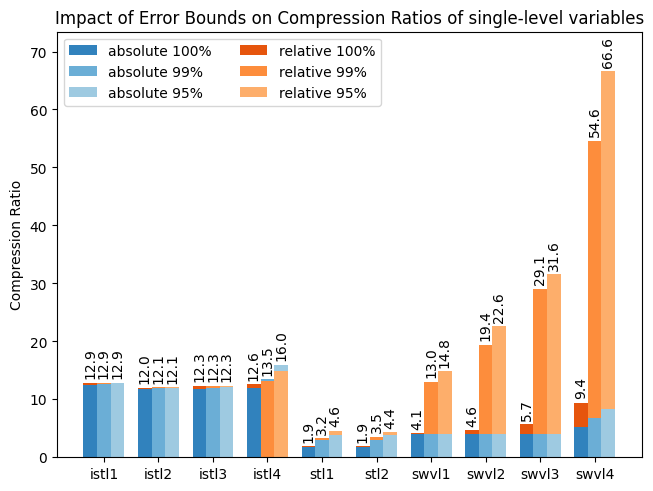

In [7]:
percentiles = ["100%", "99%", "95%"]
variables = sorted(table[table["level"] == "single"]["var"].unique()[:10])

x = np.arange(len(variables))
width = 0.25

fig, ax = plt.subplots(layout="constrained")

abs_handles = []
rel_handles = []

multiplier = 0
for i, p in enumerate(percentiles):
    offset = width * multiplier

    cr_abs = [compression_ratio_pick_single(var, p, pick="absolute") for var in variables]
    cr_rel = [compression_ratio_pick_single(var, p, pick="relative") for var in variables]
    
    rects = ax.bar(
        x + offset,
        [ca if ca < cb else ca - cb for ca, cb in zip(cr_abs, cr_rel)],
        width,
        label=f"absolute {p}",
        bottom=[0.0 if ca < cb else cb for ca, cb in zip(cr_abs, cr_rel)],
        color=tab20c[0+i],
    )
    abs_handles.append(rects)
    ax.bar_label(
        rects,
        labels=[f"{np.round(ca, 1)}" if ca > cb else "" for ca, cb in zip(cr_abs, cr_rel)],
        padding=3,
        rotation="vertical",
    )

    rects = ax.bar(
        x + offset,
        [cb if cb < ca else cb - ca for ca, cb in zip(cr_abs, cr_rel)],
        width,
        label=f"relative {p}",
        bottom=[0.0 if cb < ca else ca for ca, cb in zip(cr_abs, cr_rel)],
        color=tab20c[4+i],
    )
    rel_handles.append(rects)
    ax.bar_label(
        rects,
        labels=[f"{np.round(cb, 1)}" if cb > ca else "" for ca, cb in zip(cr_abs, cr_rel)],
        padding=3,
        rotation="vertical",
    )
    
    multiplier += 1

ax.set_ylim(0.0, ax.set_ylim()[1] * 1.05)
ax.set_ylabel("Compression Ratio")
ax.set_title("Impact of Error Bounds on Compression Ratios of single-level variables")
ax.set_xticks(x + width, variables)
ax.legend(handles=abs_handles+rel_handles, ncol=2)

plt.show()

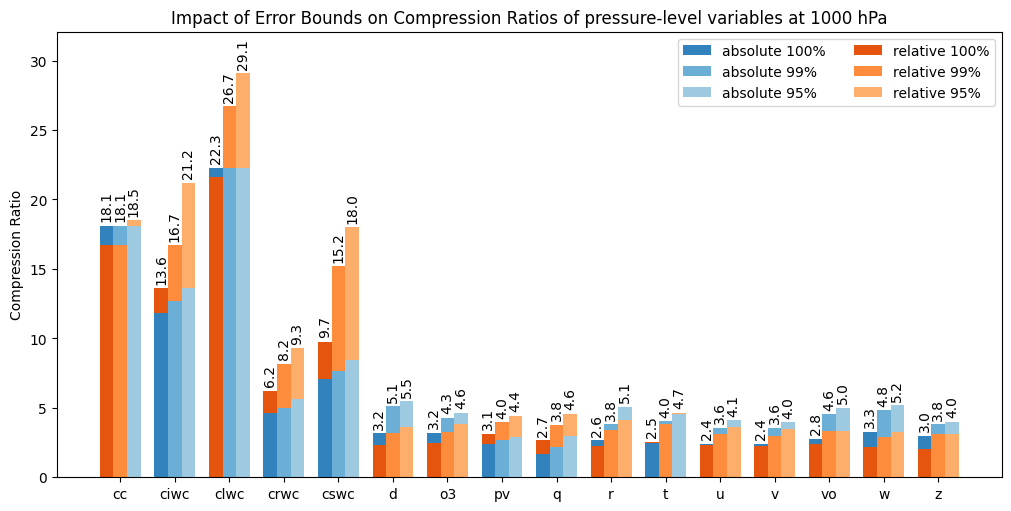

In [8]:
percentiles = ["100%", "99%", "95%"]
variables = sorted(table[table["level"] != "single"]["var"].unique())

x = np.arange(len(variables))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

abs_handles = []
rel_handles = []

multiplier = 0
for i, p in enumerate(percentiles):
    offset = width * multiplier

    cr_abs = [compression_ratio_pick_pressure(var, "1000.0 hPa", p, pick="absolute") for var in variables]
    cr_rel = [compression_ratio_pick_pressure(var, "1000.0 hPa", p, pick="relative") for var in variables]
    
    rects = ax.bar(
        x + offset,
        [ca if ca < cb else ca - cb for ca, cb in zip(cr_abs, cr_rel)],
        width,
        label=f"absolute {p}",
        bottom=[0.0 if ca < cb else cb for ca, cb in zip(cr_abs, cr_rel)],
        color=tab20c[0+i],
    )
    abs_handles.append(rects)
    ax.bar_label(
        rects,
        labels=[f"{np.round(ca, 1)}" if ca > cb else "" for ca, cb in zip(cr_abs, cr_rel)],
        padding=3,
        rotation="vertical",
    )

    rects = ax.bar(
        x + offset,
        [cb if cb < ca else cb - ca for ca, cb in zip(cr_abs, cr_rel)],
        width,
        label=f"relative {p}",
        bottom=[0.0 if cb < ca else ca for ca, cb in zip(cr_abs, cr_rel)],
        color=tab20c[4+i],
    )
    rel_handles.append(rects)
    ax.bar_label(
        rects,
        labels=[f"{np.round(cb, 1)}" if cb > ca else "" for ca, cb in zip(cr_abs, cr_rel)],
        padding=3,
        rotation="vertical",
    )
    
    multiplier += 1

ax.set_ylim(0.0, ax.set_ylim()[1] * 1.05)
ax.set_ylabel("Compression Ratio")
ax.set_title("Impact of Error Bounds on Compression Ratios of pressure-level variables at 1000 hPa")
ax.set_xticks(x + width, variables)
ax.legend(handles=abs_handles+rel_handles, ncol=2)

plt.show()